# Ensemble: soft voting across models

`compare.ipynb` picks one model per task. Here we average the class probabilities of three models,
the same soft voting a Random Forest uses inside its trees:

    P(class | x) = w_kNN · P_kNN + w_NN · P_NN + w_RF · P_RF     (weights ≥ 0, sum 1, prediction = argmax)

| Model | Probability | Settings from |
|---|---|---|
| k-NN | share of the weighted neighbour votes per class | `knn/knn.ipynb` |
| Neural Network | softmax output, averaged over 5 seeds | `neural_network/neural_network.ipynb` |
| Random Forest | average leaf class shares of 500 trees | `random_forest/random_forest.ipynb` |

Weights are chosen on the validation split. To check they are not over-fitted to it, we also choose them on one half
of the validation rows and score on the other half.

In [1]:
import os
import sys

if not os.path.exists("common.py"):      # run from the project folder
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import itertools
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

import common

common.set_seed(42)
torch.set_num_threads(min(8, os.cpu_count()))
TASKS = ["image", "sentiment"]
N_CLASSES = common.N_CLASSES

DATA, TEST, SPLIT = {}, {}, {}
for task in TASKS:
    X, y, X_test, test_ids = common.load_task(task)
    DATA[task], TEST[task] = (X, y), (X_test, test_ids)
    tr, va = common.stratified_split(y)
    SPLIT[task] = (tr, va)

## 1. k-NN class probabilities

Best settings from `knn/knn.ipynb` (distance, preprocessing, `k`, weight `1 / distance^power`);
we keep the share of weighted votes per class instead of only the winner.

In [2]:
KNN_BEST = pd.concat([pd.read_csv(f"knn/outputs/{t}_experiments.csv").sort_values("val_acc", ascending=False).head(1)
                     for t in TASKS]).set_index("task")      # best k-NN row per task


def chi_squared_matrix(A, B, chunk=25):
    """Chi-squared distance between all rows of A and B (same as chi_squared() in knn.ipynb)."""
    P = A / (A.sum(1, keepdims=True) + 1e-12)
    Q = B / (B.sum(1, keepdims=True) + 1e-12)
    D = np.empty((len(A), len(B)), dtype=np.float32)
    for i in range(0, len(A), chunk):
        p = P[i:i + chunk, None, :]
        D[i:i + chunk] = 0.5 * ((Q[None] - p) ** 2 / (Q[None] + p + 1e-12)).sum(2)
    return D


def cosine_matrix(A, B):
    A = A / (np.linalg.norm(A, axis=1, keepdims=True) + 1e-12)
    B = B / (np.linalg.norm(B, axis=1, keepdims=True) + 1e-12)
    return 1 - A @ B.T


def euclidean_matrix(A, B):
    return np.sqrt(np.maximum((A ** 2).sum(1)[:, None] + (B ** 2).sum(1)[None] - 2 * A @ B.T, 0))


DIST = {"chi_squared": chi_squared_matrix, "cosine": cosine_matrix, "euclidean": euclidean_matrix}


def knn_proba(task, X_train, y_train, X_query):
    b = KNN_BEST.loc[task]
    stats = common.fit_preprocessing(X_train, b["preprocess"])
    A = common.apply_preprocessing(X_train, b["preprocess"], stats)
    Q = common.apply_preprocessing(X_query, b["preprocess"], stats)
    with np.errstate(all="ignore"):          # numpy 2.0 on macOS prints false matmul warnings
        D = DIST[b["distance"]](Q, A)
    k, power = int(b["k"]), int(b["power"])
    idx = np.argpartition(D, k, axis=1)[:, :k]                      # the k nearest training rows
    d = np.take_along_axis(D, idx, axis=1).astype(np.float64)
    if power == 0:
        w = np.ones_like(d)
    else:
        # 1 / d^power, rescaled per row by the smallest distance to avoid overflow (same vote shares)
        d = d + 1e-8
        w = (d.min(axis=1, keepdims=True) / d) ** power
    proba = np.zeros((len(Q), N_CLASSES[task]))
    for c in range(N_CLASSES[task]):
        proba[:, c] = (w * (y_train[idx] == c)).sum(1)
    proba = proba / proba.sum(1, keepdims=True)
    assert np.isfinite(proba).all()
    return proba


VAL, TESTP = {t: {} for t in TASKS}, {t: {} for t in TASKS}
for task in TASKS:
    (X, y), (X_test, _), (tr, va) = DATA[task], TEST[task], SPLIT[task]
    start = time.time()
    VAL[task]["k-NN"] = knn_proba(task, X[tr], y[tr], X[va])
    TESTP[task]["k-NN"] = knn_proba(task, X, y, X_test)            # test: neighbours among all training rows
    acc = common.accuracy(y[va], VAL[task]["k-NN"].argmax(1))
    print(f"{task:<9} k-NN validation accuracy {acc:.4f}   (k-NN notebook: {KNN_BEST.loc[task, 'val_acc']:.4f})  {time.time() - start:.0f}s")

image     k-NN validation accuracy 0.6008   (k-NN notebook: 0.6008)  41s


sentiment k-NN validation accuracy 0.6000   (k-NN notebook: 0.6000)  1s


## 2. Neural Network class probabilities

Same network, training loop and best settings as `neural_network.ipynb`; for the test set it is retrained on all
training rows for the best number of epochs. 5 seeds are averaged to reduce the effect of the random start.

In [3]:
ACTIVATIONS = {"relu": nn.ReLU, "tanh": nn.Tanh, "sigmoid": nn.Sigmoid}


class Network(nn.Module):                      # identical to neural_network.ipynb
    def __init__(self, n_inputs, n_outputs, hidden_sizes, activation="relu", dropout=0.0, input_dropout=0.0):
        super().__init__()
        layers = [nn.Dropout(input_dropout)] if input_dropout > 0 else []
        size = n_inputs
        for hidden in hidden_sizes:
            layers += [nn.Linear(size, hidden), ACTIVATIONS[activation]()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            size = hidden
        layers.append(nn.Linear(size, n_outputs))
        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        return self.layers(x)


# best settings from neural_network.ipynb
NN_BEST = {
    "sentiment": {"preprocess": "none", "hidden_sizes": [256, 64], "activation": "relu", "dropout": 0.5,
                  "input_dropout": 0.2, "lr": 1e-4, "weight_decay": 1e-2, "batch_size": 128,
                  "max_epochs": 100, "patience": 10},
    "image": {"preprocess": "none", "hidden_sizes": [1024], "activation": "relu", "dropout": 0.0,
              "input_dropout": 0.2, "lr": 1e-3, "weight_decay": 1e-2, "batch_size": 128,
              "max_epochs": 100, "patience": 10},
}
SEEDS = [42, 43, 44, 45, 46]


def fit_network(task, s, X_tr, y_tr, seed, X_va=None, y_va=None, n_epochs=None):
    """Train one network: early stopping if validation data is given, else exactly n_epochs."""
    common.set_seed(seed)
    X_tr, y_tr = torch.tensor(X_tr), torch.tensor(y_tr)
    model = Network(X_tr.shape[1], N_CLASSES[task], s["hidden_sizes"], s["activation"], s["dropout"], s["input_dropout"])
    opt = torch.optim.AdamW(model.parameters(), lr=s["lr"], weight_decay=s["weight_decay"])
    loss_fn = nn.CrossEntropyLoss()
    best, best_epoch, best_w = -1, 0, None
    for epoch in range(1, (n_epochs or s["max_epochs"]) + 1):
        model.train()
        order = torch.randperm(len(X_tr))
        for i in range(0, len(X_tr), s["batch_size"]):
            b = order[i:i + s["batch_size"]]
            opt.zero_grad(); loss_fn(model(X_tr[b]), y_tr[b]).backward(); opt.step()
        if X_va is not None:
            model.eval()
            with torch.no_grad():
                acc = (model(torch.tensor(X_va)).argmax(1).numpy() == y_va).mean()
            if acc > best:
                best, best_epoch, best_w = acc, epoch, {k: v.clone() for k, v in model.state_dict().items()}
            elif epoch - best_epoch >= s["patience"]:
                break
    if best_w is not None:
        model.load_state_dict(best_w)
    model.eval()
    return model, best_epoch


def softmax_of(model, X):
    with torch.no_grad():
        return torch.softmax(model(torch.tensor(X)), dim=1).numpy()


for task in TASKS:
    s = NN_BEST[task]
    (X, y), (X_test, _), (tr, va) = DATA[task], TEST[task], SPLIT[task]
    st = common.fit_preprocessing(X[tr], s["preprocess"])
    Xtr, Xva = common.apply_preprocessing(X[tr], s["preprocess"], st), common.apply_preprocessing(X[va], s["preprocess"], st)
    st_all = common.fit_preprocessing(X, s["preprocess"])
    Xall, Xte = common.apply_preprocessing(X, s["preprocess"], st_all), common.apply_preprocessing(X_test, s["preprocess"], st_all)
    start = time.time()
    val_list, test_list, single = [], [], []
    for seed in SEEDS:
        model, best_epoch = fit_network(task, s, Xtr, y[tr], seed, Xva, y[va])
        val_list.append(softmax_of(model, Xva))
        single.append(common.accuracy(y[va], val_list[-1].argmax(1)))
        final, _ = fit_network(task, s, Xall, y, seed, n_epochs=best_epoch)     # retrain on all rows
        test_list.append(softmax_of(final, Xte))
    VAL[task]["Neural Network"] = np.mean(val_list, axis=0)
    TESTP[task]["Neural Network"] = np.mean(test_list, axis=0)
    acc = common.accuracy(y[va], VAL[task]["Neural Network"].argmax(1))
    print(f"{task:<9} NN single seeds {np.round(single, 4)}  ->  {len(SEEDS)}-seed average {acc:.4f}   ({time.time() - start:.0f}s)")

image     NN single seeds [0.4582 0.45   0.4555 0.4515 0.448 ]  ->  5-seed average 0.4800   (177s)


sentiment NN single seeds [0.6862 0.6854 0.6854 0.6821 0.685 ]  ->  5-seed average 0.6829   (40s)


## 3. Random Forest class probabilities (saved by `random_forest.ipynb`)

In [4]:
for task in TASKS:
    y, va = DATA[task][1], SPLIT[task][1]
    VAL[task]["Random Forest"] = np.load(f"random_forest/outputs/{task}_val_proba.npy")
    TESTP[task]["Random Forest"] = np.load(f"random_forest/outputs/{task}_test_proba.npy")
    print(f"{task:<9} Random Forest validation accuracy {common.accuracy(y[va], VAL[task]['Random Forest'].argmax(1)):.4f}")

image     Random Forest validation accuracy 0.3685
sentiment Random Forest validation accuracy 0.6708


## 4. Choosing the weights

Every weight triple on a 0.05 grid (231 combinations); the best one is kept per task.

,task,k-NN,Neural Network,Random Forest,ensemble,"weights (kNN, NN, RF)",gain on held-out half (2 folds)
0,image,0.6008,0.4800,0.3685,0.6358,"(0.35, 0.15, 0.5)","[0.0385, 0.0315]"
1,sentiment,0.6000,0.6829,0.6708,0.6879,"(0.2, 0.6, 0.2)","[0.0042, 0.0017]"


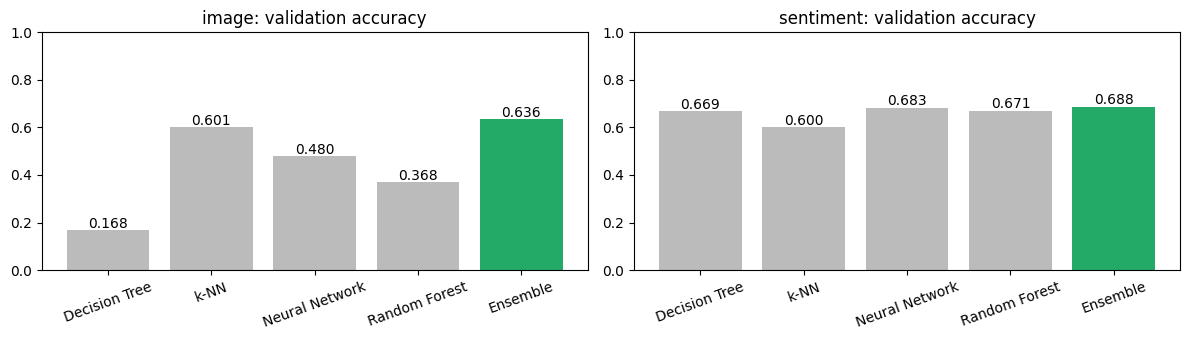

In [5]:
MODELS = ["k-NN", "Neural Network", "Random Forest"]
GRID = [w for w in itertools.product(np.round(np.arange(0, 1.0001, 0.05), 2), repeat=3) if abs(sum(w) - 1) < 1e-9]


def ensemble(probas, w):
    return sum(wi * p for wi, p in zip(w, probas))


def best_weights(probas, y, rows=None):
    rows = np.arange(len(y)) if rows is None else rows
    scored = [(common.accuracy(y[rows], ensemble([p[rows] for p in probas], w).argmax(1)), w) for w in GRID]
    return max(scored, key=lambda t: (round(t[0], 6), max(t[1])))     # ties -> the simpler (more one-sided) mix


CHOSEN, rows = {}, []
for task in TASKS:
    y_va = DATA[task][1][SPLIT[task][1]]
    probas = [VAL[task][m] for m in MODELS]
    singles = {m: common.accuracy(y_va, VAL[task][m].argmax(1)) for m in MODELS}
    acc, w = best_weights(probas, y_va)
    CHOSEN[task] = w

    # stability: choose on one half, score on the other half
    rng = np.random.default_rng(0)
    half = rng.permutation(len(y_va)); A, B = half[: len(half) // 2], half[len(half) // 2:]
    best_single = max(singles, key=singles.get)
    held = []
    for fit_rows, eval_rows in [(A, B), (B, A)]:
        _, w_half = best_weights(probas, y_va, fit_rows)
        ens = common.accuracy(y_va[eval_rows], ensemble([p[eval_rows] for p in probas], w_half).argmax(1))
        single = common.accuracy(y_va[eval_rows], VAL[task][best_single][eval_rows].argmax(1))
        held.append(ens - single)
    rows.append({"task": task, **{f"{m}": round(a, 4) for m, a in singles.items()},
                 "ensemble": round(acc, 4), "weights (kNN, NN, RF)": w,
                 "gain on held-out half (2 folds)": [round(h, 4) for h in held]})
table = pd.DataFrame(rows)
display(table)

import matplotlib.pyplot as plt
os.makedirs("report/figures", exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))      # validation accuracy of every model
for ax, task in zip(axes, TASKS):
    y_va = DATA[task][1][SPLIT[task][1]]
    names = ["Decision Tree"] + MODELS + ["Ensemble"]
    accs = [common.accuracy(y_va, np.load(f"decision_tree/outputs/{task}_val_pred.npy"))]
    accs += [common.accuracy(y_va, VAL[task][m].argmax(1)) for m in MODELS]
    accs += [common.accuracy(y_va, ensemble([VAL[task][m] for m in MODELS], CHOSEN[task]).argmax(1))]
    ax.bar(names, accs, color=["#bbb"] * 4 + ["#2a6"])
    for i, a in enumerate(accs):
        ax.text(i, a + 0.01, f"{a:.3f}", ha="center")
    ax.set_ylim(0, 1); ax.set_title(f"{task}: validation accuracy"); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig("report/figures/model_comparison.png", dpi=150); plt.show()

`gain on held-out half` = ensemble minus best single model, on validation rows not used to choose the weights.

## 5. Rows fixed and broken by the ensemble

In [6]:
for task in TASKS:
    y_va = DATA[task][1][SPLIT[task][1]]
    ens_pred = ensemble([VAL[task][m] for m in MODELS], CHOSEN[task]).argmax(1)
    best_single = max(MODELS, key=lambda m: common.accuracy(y_va, VAL[task][m].argmax(1)))
    single_pred = VAL[task][best_single].argmax(1)
    fixed = np.sum((ens_pred == y_va) & (single_pred != y_va))
    broken = np.sum((ens_pred != y_va) & (single_pred == y_va))
    print(f"{task}: vs {best_single}: ensemble fixes {fixed} rows and breaks {broken} rows (net {fixed - broken:+d} of {len(y_va)})")
    if task == "sentiment":
        for name, pred in [(best_single, single_pred), ("ensemble", ens_pred)]:
            r = common.per_class_recall(common.confusion_matrix(y_va, pred, 3))
            print(f"   {name:<15} recall  " + "  ".join(f"{n} {v:.3f}" for n, v in zip(common.SENTIMENT_NAMES, r)))

image: vs k-NN: ensemble fixes 262 rows and breaks 122 rows (net +140 of 4000)
sentiment: vs Neural Network: ensemble fixes 37 rows and breaks 25 rows (net +12 of 2400)
   Neural Network  recall  Negative 0.809  Neutral 0.535  Positive 0.705
   ensemble        recall  Negative 0.815  Neutral 0.547  Positive 0.701


## 6. Kaggle file

Test probabilities come from models refitted on all training rows. Expected score = mean of the two validation accuracies.

In [7]:
preds, expected = {}, []
for task in TASKS:
    preds[task] = ensemble([TESTP[task][m] for m in MODELS], CHOSEN[task]).argmax(1)
    y_va = DATA[task][1][SPLIT[task][1]]
    expected.append(common.accuracy(y_va, ensemble([VAL[task][m] for m in MODELS], CHOSEN[task]).argmax(1)))

path = "final/submissions/ensemble_soft_voting.csv"
common.make_submission(TEST["image"][1], preds["image"], TEST["sentiment"][1], preds["sentiment"], path)
print(f"saved {path}   expected score {np.mean(expected):.4f}  (image {expected[0]:.4f}, sentiment {expected[1]:.4f})")
print("best single-model file (compare.ipynb):", pd.read_csv("final/submissions/expected_scores.csv").iloc[0].to_dict())

for task in TASKS:     # sanity check against the current best single-model file
    single = pd.read_csv(f"{'knn' if task == 'image' else 'neural_network'}/outputs/{task}_test_pred.csv")
    agree = (single["label"].to_numpy() == preds[task]).mean()
    print(f"{task}: ensemble agrees with the current submission on {agree:.1%} of test rows; "
          f"predicted class counts min {np.bincount(preds[task]).min()} max {np.bincount(preds[task]).max()}")

saved final/submissions/ensemble_soft_voting.csv   expected score 0.6618  (image 0.6358, sentiment 0.6879)
best single-model file (compare.ipynb): {'image model': 'k-NN', 'sentiment model': 'Neural Network', 'expected score': 0.6437, 'file': 'final/submissions/image_knn__sentiment_neural_network.csv'}
image: ensemble agrees with the current submission on 80.3% of test rows; predicted class counts min 74 max 133
sentiment: ensemble agrees with the current submission on 95.4% of test rows; predicted class counts min 1206 max 2462
